# A Comparative Study of Resampling and Cost-Sensitive Learning
## for Imbalanced Credit Card Fraud Detection

**Presented by:** Abdouramane Soudaysi · Youssouf Doumbia · Alimata Zoungrana
**Supervised by:** Ashraful Alam Khan · Dr. Md. Azam Hossain — CSE Department, IUT

---

This notebook merges and extends two earlier working notebooks
(`Credit_Card_Fraud_Detection_Analysis.ipynb` and `Credit_Card_Fraud_Detection_Complete.ipynb`)
into a single, thesis-aligned notebook. Section numbering below follows the
**"Results and Analysis"** chapter of the thesis exactly:

```
4.1  Exploratory Data Analysis
     4.1.1  Class Distribution Visualisation
     4.1.2  Feature Correlation and Importance
4.2  Baseline Model Performance (No Treatment)
4.3  Performance of Resampling Methods
     4.3.1  Results with Random Oversampling
     4.3.2  Results with SMOTE
     4.3.3  Results with ADASYN
4.4  Results with Random Undersampling
     4.4.1  Result with Edited Nearest Neighbours (ENN)
     4.4.2  Result with Tomek Links
4.5  Performance of Cost-Sensitive Methods
     4.5.1  Results with Class-Weight Adjustment
     4.5.2  Results with Cost-Sensitive Classifiers
4.6  Cross-Method Comparison
     4.6.1  Summary Comparison Table
     4.6.2  Statistical Significance Testing
4.7  Best-Performing Combination Identified
```

**Pipeline**
```
Dataset → EDA → Preprocessing → Stratified Split
                                      │
   ┌───────────────┬──────────────────┼──────────────────┬───────────────┐
   │               │                  │                  │               │
Baseline      Oversampling      Undersampling      Cost-Sensitive     (all four
(No treat.)  (Random/SMOTE/     (Random/ENN/        (Class-Weight /    branches
              ADASYN)            Tomek Links)         Custom Cost-     feed the
   │               │                  │              Matrix+Threshold) same
   └───────────────┴──────────────────┴──────────────────┴───────────────┘
                                      ▼
        Models: Logistic Regression | Random Forest | Gradient Boosting
                                      ▼
              Metrics: Precision · Recall · F1 · AUC-ROC · Accuracy
                                      ▼
        Cross-Method Comparison → Significance Testing → Best Combination
```

> **Note on the dataset:** this notebook expects the ULB "Credit Card Fraud
> Detection" dataset (`creditcard.csv`, 284,807 transactions, 492 frauds) to be
> present in the working directory. Download it from Kaggle
> (`mlg-ulb/creditcardfraud`) and place it next to this notebook before running.

> **Note on runtime:** several resampled training sets contain ~400,000 rows.
> Gradient Boosting and Edited-Nearest-Neighbours / Tomek-Links can each take a
> few minutes on such sets. This is expected — let the cells finish running.


## 1. Import Libraries

In [18]:
# ── Standard libraries ──────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter('ignore')
%matplotlib inline

# ── Sklearn : preprocessing & splitting ─────────────────────────────────────
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer
from sklearn.utils.class_weight import compute_sample_weight

# ── Imbalanced-learn : resampling ───────────────────────────────────────────
from imblearn.under_sampling import RandomUnderSampler, EditedNearestNeighbours, TomekLinks
from imblearn.over_sampling  import RandomOverSampler, SMOTE, ADASYN

# ── Models ───────────────────────────────────────────────────────────────────
from sklearn.linear_model    import LogisticRegression
from sklearn.ensemble        import RandomForestClassifier, GradientBoostingClassifier

# ── Metrics ──────────────────────────────────────────────────────────────────
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve,
    precision_recall_curve, auc,
    average_precision_score,
    accuracy_score
)

# ── Statistics (significance testing, Section 4.6.2) ────────────────────────
from scipy import stats

print('All libraries imported successfully')


All libraries imported successfully


## 2. Load & Inspect Dataset

In [19]:
df = pd.read_csv('creditcard.csv')
print(f'Shape : {df.shape}')
df.head()


Shape : (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [20]:
df.info(verbose=True)


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [21]:
print('Missing values :', df.isnull().sum().sum())
print('Duplicate rows :', df.duplicated().sum())


Missing values : 0
Duplicate rows : 1081


## 4.1 Exploratory Data Analysis

### 4.1.1 Class Distribution Visualisation

In [22]:
# ── Class distribution ──────────────────────────────────────────────────────
classes       = df['Class'].value_counts()
normal_share  = classes[0] / len(df) * 100
fraud_share   = classes[1] / len(df) * 100

print(f'Non-Fraudulent : {classes[0]:,}  ({normal_share:.3f}%)')
print(f'Fraudulent     : {classes[1]:,}  ({fraud_share:.3f}%)')
print(f'Imbalance ratio: {classes[0]/classes[1]:.0f}:1')


Non-Fraudulent : 284,315  (99.827%)
Fraudulent     : 492  (0.173%)
Imbalance ratio: 578:1


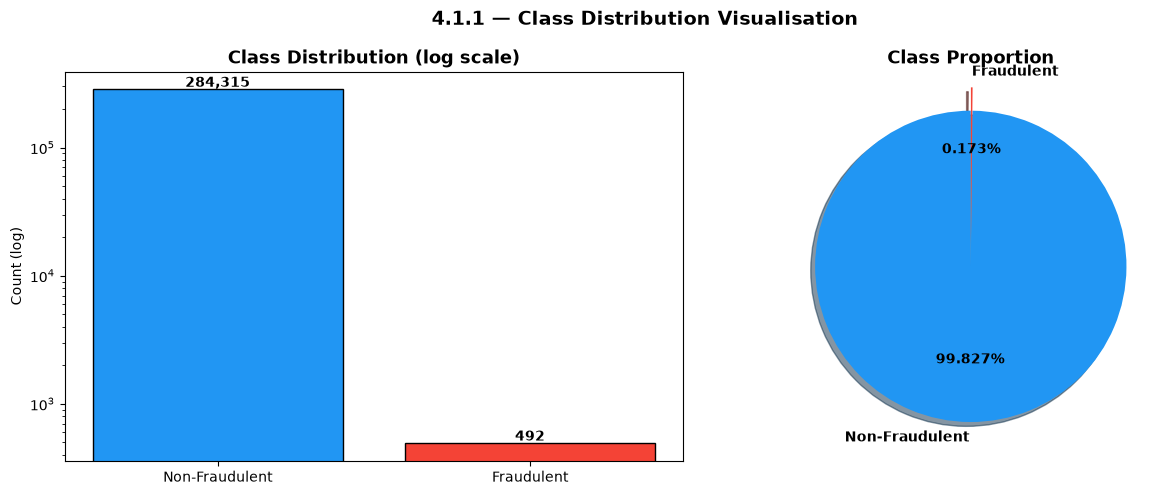

In [23]:
# ── Bar + Pie chart ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ['#2196F3', '#F44336']

# Bar
axes[0].bar(['Non-Fraudulent', 'Fraudulent'], [classes[0], classes[1]],
            color=colors, edgecolor='black')
axes[0].set_yscale('log')
axes[0].set_title('Class Distribution (log scale)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count (log)')
for i, v in enumerate([classes[0], classes[1]]):
    axes[0].text(i, v * 1.05, f'{v:,}', ha='center', fontweight='bold')

# Pie
axes[1].pie([classes[0], classes[1]], labels=['Non-Fraudulent', 'Fraudulent'],
            autopct='%1.3f%%', colors=colors, startangle=90,
            explode=(0, 0.15), shadow=True, textprops={'fontweight': 'bold'})
axes[1].set_title('Class Proportion', fontsize=13, fontweight='bold')

plt.suptitle('4.1.1 — Class Distribution Visualisation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig01_class_distribution.png', bbox_inches='tight', dpi=150)
plt.show()


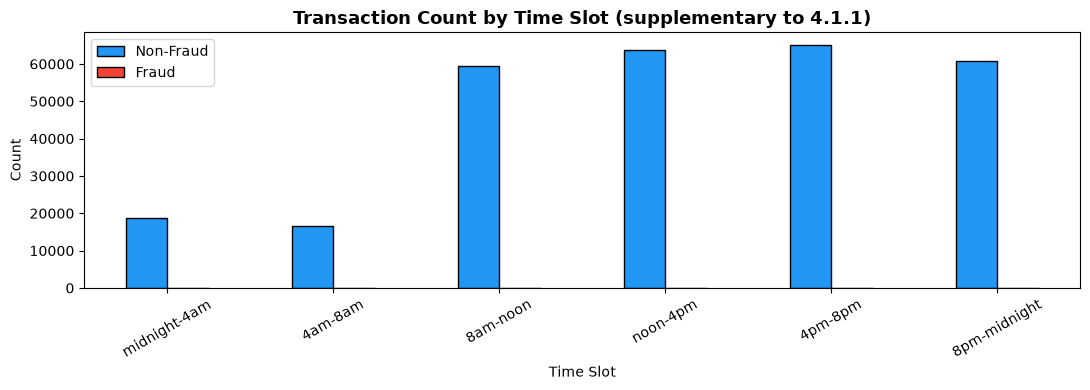

In [24]:
# ── Time-slot feature (seconds in a day = 86400) ─────────────────────────────
df['seconds_from_12_am'] = df['Time'] % 86400
bins   = [-1, 14400, 28800, 43200, 57600, 72000, 86401]
labels = ['midnight-4am', '4am-8am', '8am-noon', 'noon-4pm', '4pm-8pm', '8pm-midnight']
df['Time_Slot'] = pd.cut(df['seconds_from_12_am'], bins, labels=labels)

# Distribution of frauds per time slot
series_counts = df.groupby('Class')['Time_Slot'].value_counts().rename('count').reset_index()
pivot = series_counts.pivot(index='Time_Slot', columns='Class', values='count').fillna(0)
pivot.columns = ['Non-Fraud', 'Fraud']

ax = pivot.plot(kind='bar', figsize=(11, 4), color=['#2196F3', '#F44336'],
                edgecolor='black', rot=30)
ax.set_title('Transaction Count by Time Slot (supplementary to 4.1.1)', fontsize=13, fontweight='bold')
ax.set_xlabel('Time Slot')
ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig('fig02_time_slot_distribution.png', bbox_inches='tight', dpi=150)
plt.show()


In [25]:
# ── Amount statistics per class ───────────────────────────────────────────────
print('--- Average Amount per class ---')
print(df.groupby('Class')['Amount'].mean())
print('\n--- Max Amount per class ---')
print(df.groupby('Class')['Amount'].max())
print('\n--- Median Amount per class ---')
print(df.groupby('Class')['Amount'].median())


--- Average Amount per class ---
Class
0     88.291022
1    122.211321
Name: Amount, dtype: float64

--- Max Amount per class ---
Class
0    25691.16
1     2125.87
Name: Amount, dtype: float64

--- Median Amount per class ---
Class
0    22.00
1     9.25
Name: Amount, dtype: float64


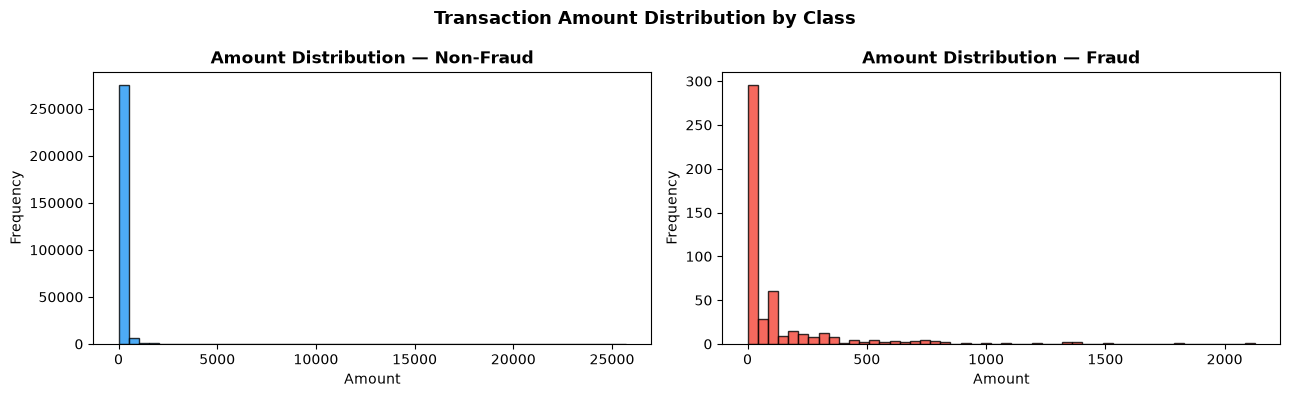

In [26]:
# ── Amount distribution by class ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (cls, label, color) in zip(axes, [(0, 'Non-Fraud', '#2196F3'), (1, 'Fraud', '#F44336')]):
    data = df[df['Class'] == cls]['Amount']
    ax.hist(data, bins=50, color=color, edgecolor='black', alpha=0.8)
    ax.set_title(f'Amount Distribution — {label}', fontweight='bold')
    ax.set_xlabel('Amount')
    ax.set_ylabel('Frequency')
plt.suptitle('Transaction Amount Distribution by Class', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig03_amount_distribution.png', bbox_inches='tight', dpi=150)
plt.show()


### 4.1.2 Feature Correlation and Importance

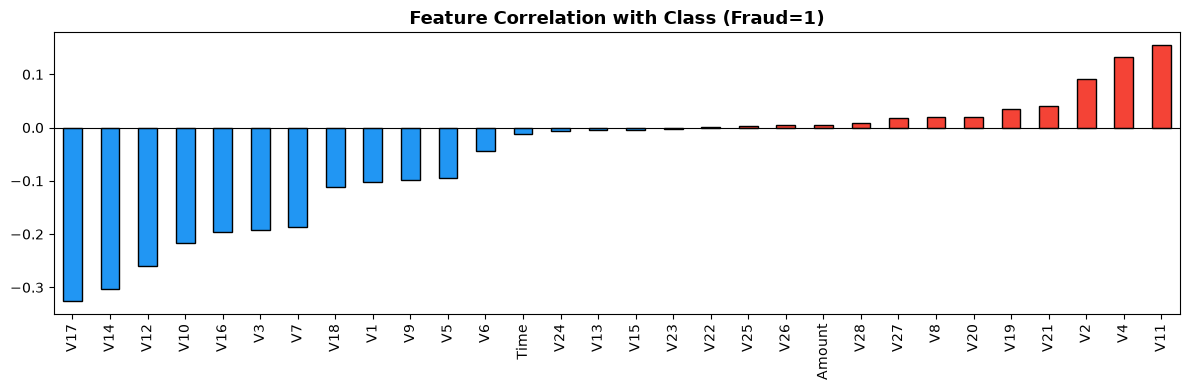

Most important features by |correlation| with Class (top 10):
V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
V7     0.187257
V11    0.154876
V4     0.133447
V18    0.111485
Name: Class, dtype: float64


In [27]:
# ── Correlation with Class ─────────────────────────────────────────────────────
# Build a numeric-only copy (drop Time_Slot object column)
df_numeric = df.drop(['seconds_from_12_am', 'Time_Slot'], axis=1)

corr = df_numeric.corr()['Class'].drop('Class').sort_values()
colors_c = ['#F44336' if v > 0 else '#2196F3' for v in corr]

plt.figure(figsize=(12, 4))
corr.plot(kind='bar', color=colors_c, edgecolor='black')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Feature Correlation with Class (Fraud=1)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig04_correlation_class.png', bbox_inches='tight', dpi=150)
plt.show()

abs_corr = corr.abs().sort_values(ascending=False)
print('Most important features by |correlation| with Class (top 10):')
print(abs_corr.head(10))


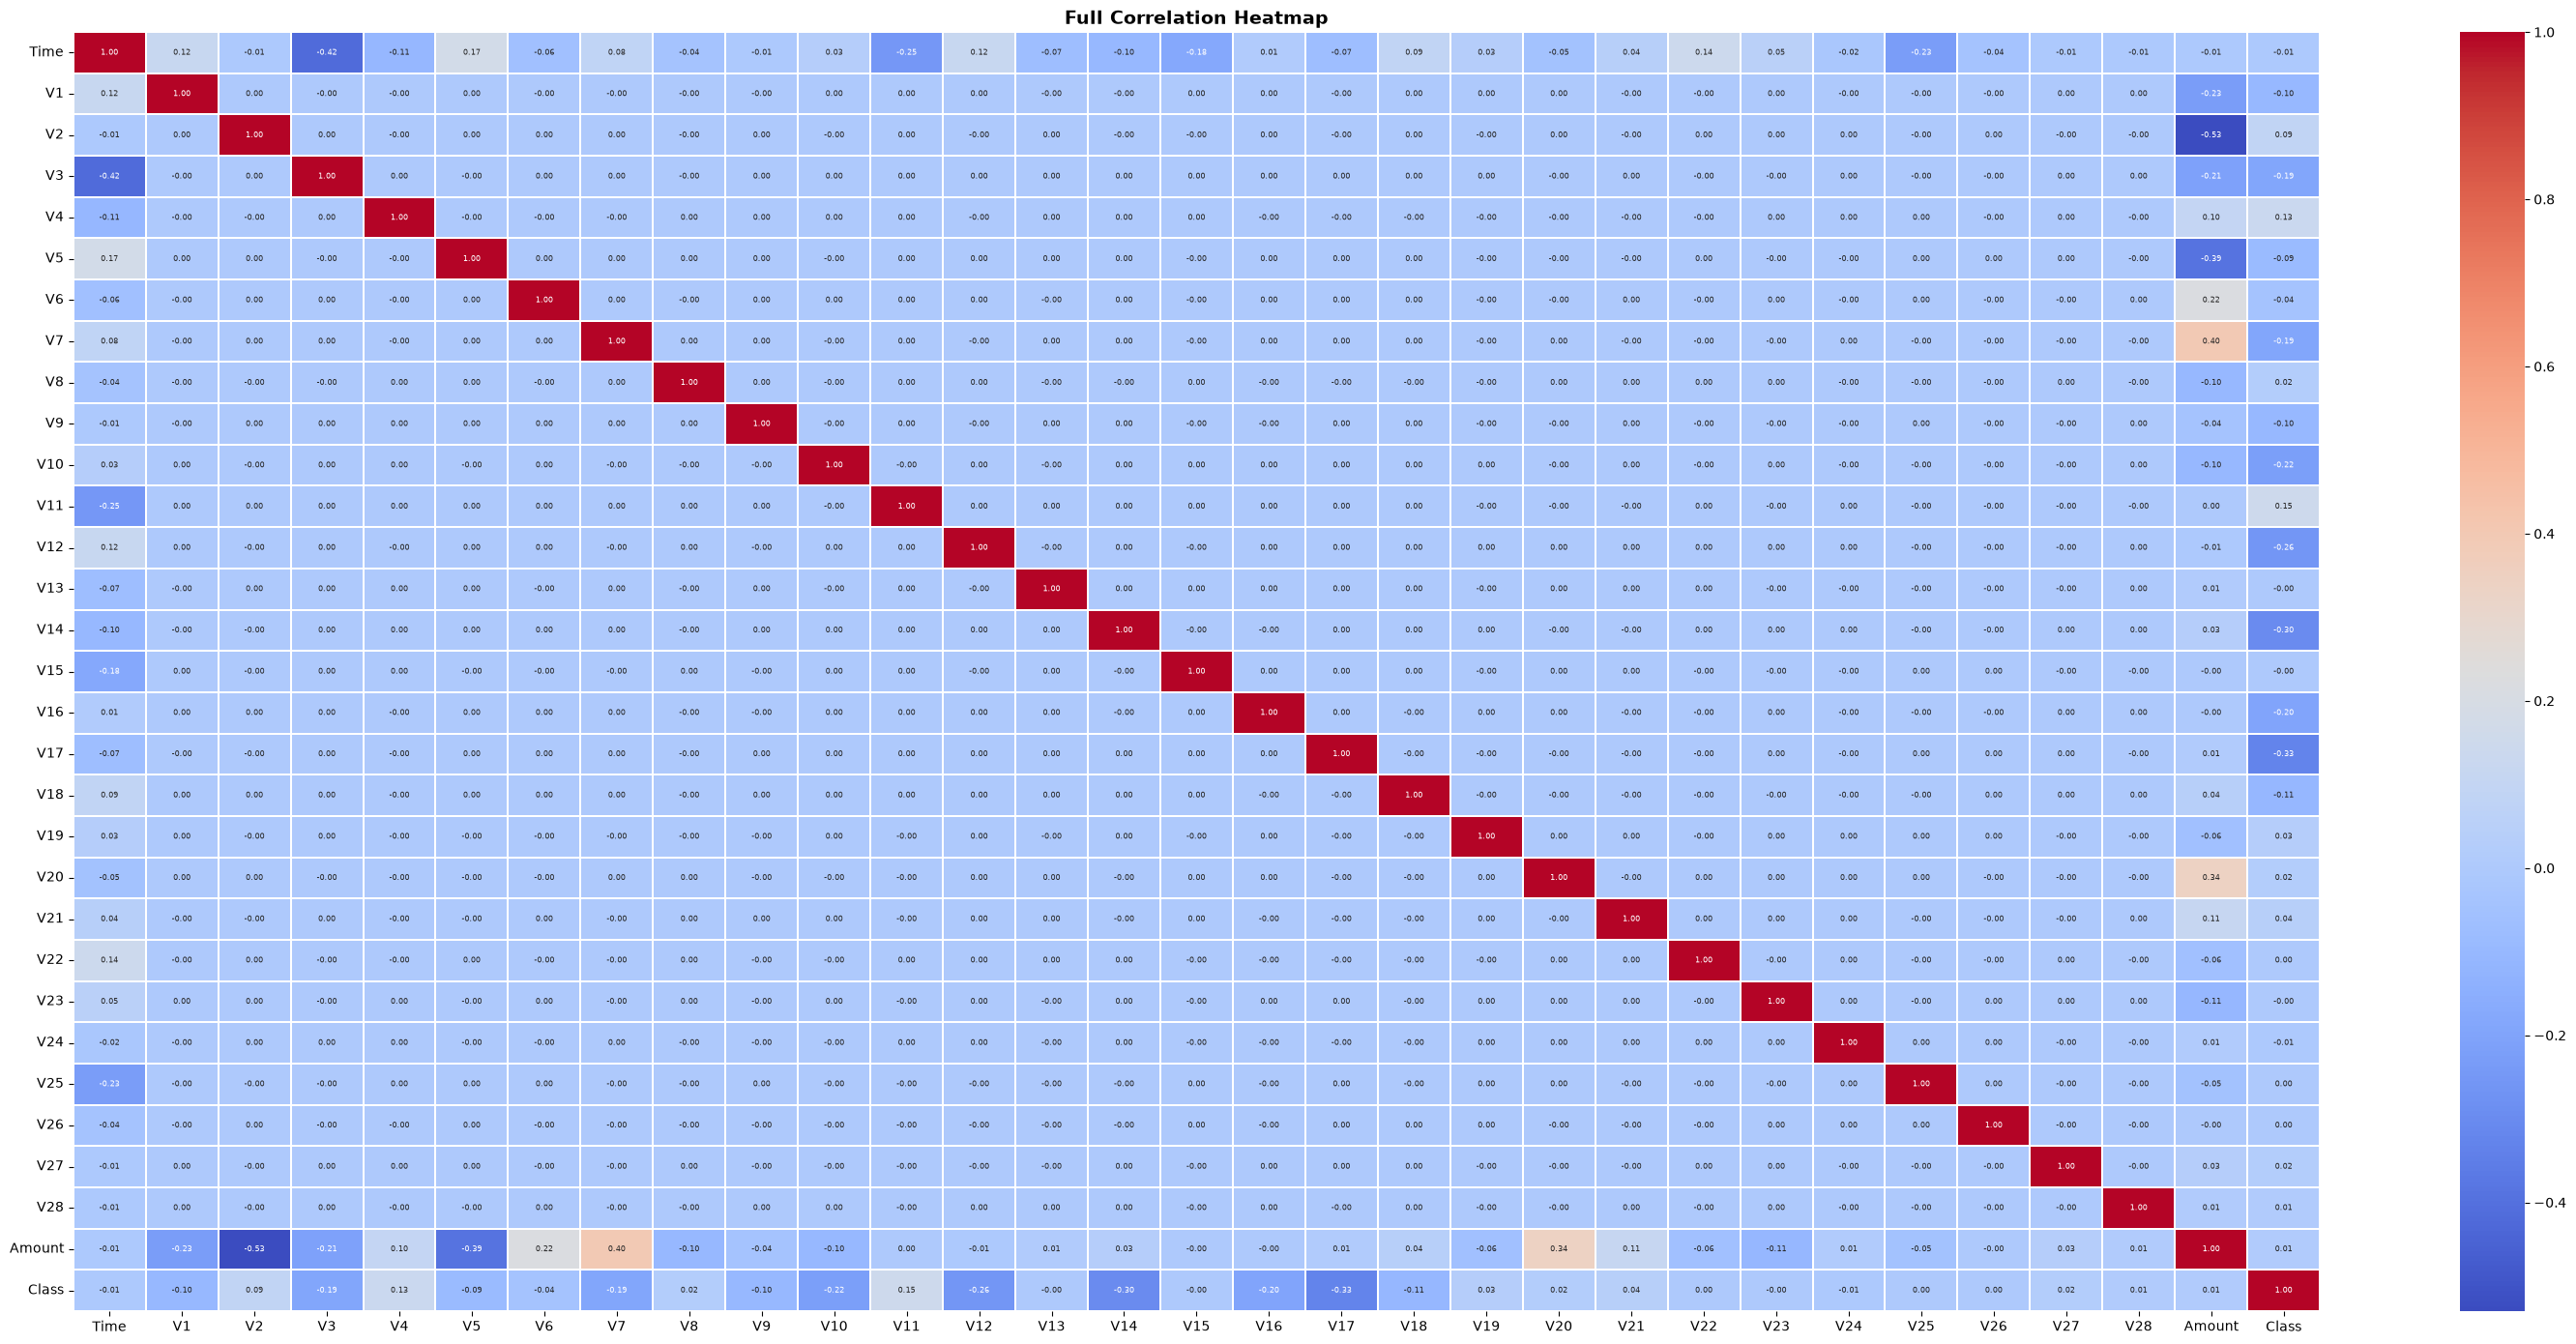

In [28]:
# ── Heatmap of all features ────────────────────────────────────────────────────
plt.figure(figsize=(30, 14))
sns.heatmap(df_numeric.corr().round(2), annot=True, fmt='.2f',
            cmap='coolwarm', linewidths=0.1, annot_kws={'size': 6})
plt.title('Full Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig05_correlation_heatmap.png', bbox_inches='tight', dpi=150)
plt.show()


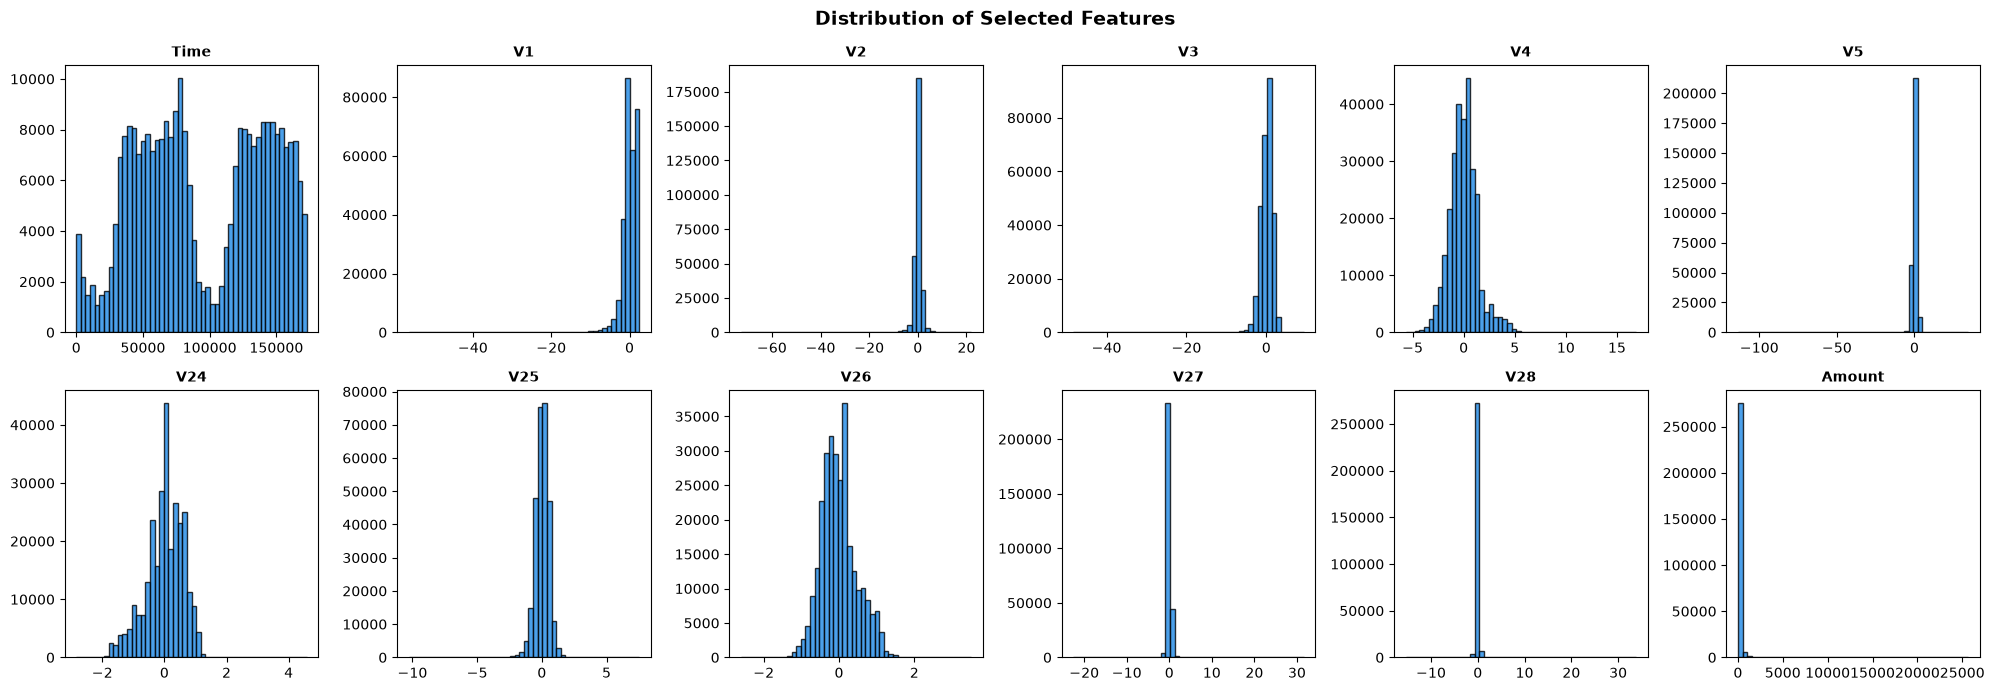


Note: a model-based feature-importance ranking (Random Forest) is produced
later in Section 4.6.1 once a treated training set is available.


In [29]:
# ── Distribution of key features ───────────────────────────────────────────────
features_to_plot = ['Time', 'V1', 'V2', 'V3', 'V4', 'V5',
                     'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
axes = axes.flatten()
for ax, feat in zip(axes, features_to_plot):
    ax.hist(df[feat], bins=50, color='#1E88E5', edgecolor='black', alpha=0.8)
    ax.set_title(feat, fontsize=10, fontweight='bold')
plt.suptitle('Distribution of Selected Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig06_feature_distributions.png', bbox_inches='tight', dpi=150)
plt.show()

print('\nNote: a model-based feature-importance ranking (Random Forest) is produced')
print('later in Section 4.6.1 once a treated training set is available.')


## Data Preprocessing
*(pipeline step between EDA and modelling — not separately numbered in the thesis,
but required before Sections 4.2–4.7 can run.)*

In [30]:
# ── One-hot encode Time_Slot ───────────────────────────────────────────────────
dummies = pd.get_dummies(df['Time_Slot'], drop_first=True)
df = pd.concat([df, dummies], axis=1)
df = df.drop(['seconds_from_12_am', 'Time_Slot'], axis=1)
print('Shape after feature engineering:', df.shape)


Shape after feature engineering: (284807, 36)


In [31]:
# ── Features / Target split ────────────────────────────────────────────────────
X = df.drop('Class', axis=1)
y = df['Class'].copy()

# Keep originals before any resampling
X_orig = X.copy()
y_orig = y.copy()

print('X shape :', X.shape, '| y shape :', y.shape)
print('Fraud :', y.sum(), '| Non-Fraud :', (y == 0).sum())


X shape : (284807, 35) | y shape : (284807,)
Fraud : 492 | Non-Fraud : 284315


In [32]:
# ── Stratified train/test split (70 / 30) ─────────────────────────────────────
X_train_raw, X_test, y_train_raw, y_test = train_test_split(
    X_orig, y_orig,
    test_size=0.3,
    random_state=100,
    stratify=y_orig
)
print(f'Train : {X_train_raw.shape[0]:,}  |  Test : {X_test.shape[0]:,}')
print(f'Train fraud : {y_train_raw.sum()}  |  Test fraud : {y_test.sum()}')


Train : 199,364  |  Test : 85,443
Train fraud : 344  |  Test fraud : 148


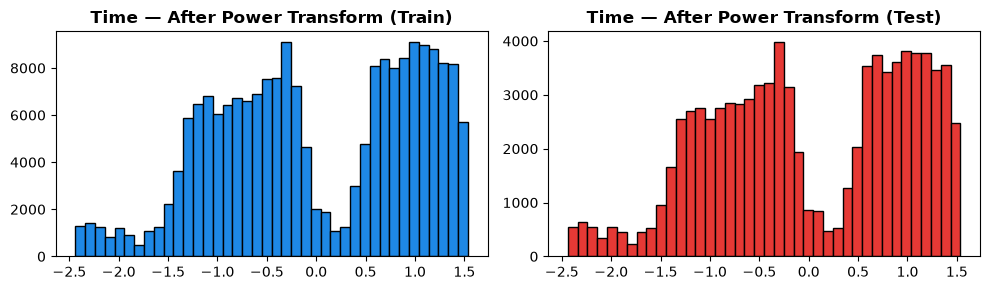

In [33]:
# ── Power Transform on Time (remove skewness) ─────────────────────────────────
pt = PowerTransformer(copy=False)
pt.fit(X_train_raw[['Time']])

X_train_raw = X_train_raw.copy()
X_test      = X_test.copy()

X_train_raw['Time'] = pt.transform(X_train_raw[['Time']])
X_test['Time']      = pt.transform(X_test[['Time']])

# Verify
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(X_train_raw['Time'], bins=40, color='#1E88E5', edgecolor='black')
axes[0].set_title('Time — After Power Transform (Train)', fontweight='bold')
axes[1].hist(X_test['Time'],      bins=40, color='#E53935', edgecolor='black')
axes[1].set_title('Time — After Power Transform (Test)',  fontweight='bold')
plt.tight_layout()
plt.savefig('fig07_time_transform.png', bbox_inches='tight', dpi=150)
plt.show()

# ── Baseline (no-treatment) training set, used throughout Section 4.2+ ────────
X_baseline = X_train_raw.copy()
y_baseline = y_train_raw.copy()


## Helper Functions — Evaluation, Model Builders & Significance Testing

In [ ]:
# ── Global container for every (Model, Approach) result across the notebook ──
all_results = []
metrics_keys = ['Model', 'Approach', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC', 'PR-AUC', 'Average-Precision', 'Accuracy']


def train_and_evaluate(model, X_tr, y_tr, X_te, y_te,
                        model_name='', approach_name='',
                        sample_weight=None, threshold=0.5, verbose=True):
    '''
    Fit `model` on (X_tr, y_tr) [optionally with sample_weight, used to make
    Gradient Boosting cost/class-sensitive since it has no class_weight param],
    predict on (X_te, y_te) at the given decision `threshold`, and return a
    dict with every metric + raw predictions (+ the fitted model, so it can be
    re-used later without refitting, e.g. for threshold-moving in 4.5.2).
    '''
    if sample_weight is not None:
        model.fit(X_tr, y_tr, sample_weight=sample_weight)
    else:
        model.fit(X_tr, y_tr)

    return evaluate_at_threshold(model, X_te, y_te, model_name, approach_name,
                                  threshold=threshold, verbose=verbose)


def evaluate_at_threshold(fitted_model, X_te, y_te, model_name='', approach_name='',
                           threshold=0.5, verbose=True):
    '''Evaluate an *already-fitted* model at a given probability threshold.'''
    y_proba = fitted_model.predict_proba(X_te)[:, 1]
    y_pred  = (y_proba >= threshold).astype(int)

    prec    = precision_score(y_te, y_pred, zero_division=0)
    rec     = recall_score(y_te, y_pred, zero_division=0)
    f1      = f1_score(y_te, y_pred, zero_division=0)
    auc_roc = roc_auc_score(y_te, y_proba)

    # Additional imbalance-aware metrics requested by supervisor
    ap_score = average_precision_score(y_te, y_proba)
    pr_precision, pr_recall, _ = precision_recall_curve(y_te, y_proba)
    pr_auc = auc(pr_recall, pr_precision)
    acc     = accuracy_score(y_te, y_pred)
    cm      = confusion_matrix(y_te, y_pred, labels=[0, 1])

    if verbose:
        tn, fp, fn, tp = cm.ravel()
        print(f'  [{model_name:<20} | {approach_name:<20}]  '
              f'P={prec*100:5.1f}%  R={rec*100:5.1f}%  '
              f'F1={f1*100:5.1f}%  AUC={auc_roc*100:5.1f}%  '
              f'(TP={tp:>3} FN={fn:>3} FP={fp:>4})')

    return {
        'Model'            : model_name,
        'Approach'         : approach_name,
        'Accuracy'         : round(acc * 100, 2),
        'Precision'        : round(prec * 100, 2),
        'Recall'           : round(rec * 100, 2),
        'F1-Score'         : round(f1 * 100, 2),
        'AUC-ROC'          : round(auc_roc * 100, 2),
        'PR-AUC'           : round(pr_auc * 100, 2),
        'Average-Precision': round(ap_score * 100, 2),
        'Threshold'        : round(threshold, 3),
        'CM'               : cm,
        'y_pred'           : y_pred,
        'y_proba'          : y_proba,
        'model'            : fitted_model,
    }


def default_model_builders(class_weight=None):
    '''Factory dict: {model_name: zero-arg callable that returns a *fresh* model}.'''
    return {
        'Logistic Regression': lambda: LogisticRegression(
            max_iter=1000, random_state=42, class_weight=class_weight),
        'Random Forest': lambda: RandomForestClassifier(
            n_estimators=100, random_state=42, n_jobs=-1, class_weight=class_weight),
        'Gradient Boosting': lambda: GradientBoostingClassifier(
            n_estimators=100, max_depth=3, random_state=42),
    }


def run_approach(approach_name, X_tr, y_tr, model_builders=None,
                  sample_weights=None, threshold=0.5, store=True):
    '''
    Train Logistic Regression, Random Forest and Gradient Boosting on
    (X_tr, y_tr), evaluate all three on the held-out test set, print a
    compact summary line per model, append to `all_results` and return the
    list of the three result dicts for this approach.
    '''
    if model_builders is None:
        model_builders = default_model_builders()
    results = []
    for mname, builder in model_builders.items():
        sw = sample_weights.get(mname) if sample_weights else None
        res = train_and_evaluate(
            builder(), X_tr, y_tr, X_test, y_test,
            model_name=mname, approach_name=approach_name,
            sample_weight=sw, threshold=threshold)
        results.append(res)
    if store:
        all_results.extend(results)
    return results


def mcnemar_test(y_true, y_pred_a, y_pred_b):
    '''
    Continuity-corrected McNemar's test for two classifiers evaluated on the
    *same* test set. Returns (chi2_statistic, p_value). Used in Section 4.6.2
    to test whether a treatment's errors differ significantly from baseline.
    '''
    y_true    = np.asarray(y_true)
    correct_a = (np.asarray(y_pred_a) == y_true)
    correct_b = (np.asarray(y_pred_b) == y_true)
    b = int(np.sum(correct_a & ~correct_b))   # a right, b wrong
    c = int(np.sum(~correct_a & correct_b))   # a wrong, b right
    n = b + c
    if n == 0:
        return 0.0, 1.0
    stat = (abs(b - c) - 1) ** 2 / n
    p    = 1 - stats.chi2.cdf(stat, df=1)
    return stat, p


print('Helper functions ready: train_and_evaluate, evaluate_at_threshold,')
print('default_model_builders, run_approach, mcnemar_test')


Helper functions ready: train_and_evaluate, evaluate_at_threshold,
default_model_builders, run_approach, mcnemar_test


## 4.2 Baseline Model Performance (No Treatment)
The three models are trained directly on the raw, highly-imbalanced training
set (≈0.17% fraud) with no resampling and no class weighting. This establishes
the reference point against which every resampling and cost-sensitive
treatment in Sections 4.3–4.5 is judged.

In [35]:
print('=' * 72)
print('  4.2  BASELINE — NO TREATMENT')
print('=' * 72)

baseline_results = run_approach('Baseline', X_baseline, y_baseline)

print()
for res in baseline_results:
    print(f"{'─'*55}")
    print(f"  Model : {res['Model']}  |  Approach : {res['Approach']}")
    print(f"{'─'*55}")
    print(classification_report(y_test, res['y_pred'], target_names=['Non-Fraud', 'Fraud']))


  4.2  BASELINE — NO TREATMENT
  [Logistic Regression  | Baseline            ]  P= 81.7%  R= 57.4%  F1= 67.5%  AUC= 96.8%  (TP= 85 FN= 63 FP=  19)
  [Random Forest        | Baseline            ]  P= 91.7%  R= 75.0%  F1= 82.5%  AUC= 94.1%  (TP=111 FN= 37 FP=  10)
  [Gradient Boosting    | Baseline            ]  P= 73.4%  R= 46.6%  F1= 57.0%  AUC= 66.9%  (TP= 69 FN= 79 FP=  25)

───────────────────────────────────────────────────────
  Model : Logistic Regression  |  Approach : Baseline
───────────────────────────────────────────────────────
              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00     85295
       Fraud       0.82      0.57      0.67       148

    accuracy                           1.00     85443
   macro avg       0.91      0.79      0.84     85443
weighted avg       1.00      1.00      1.00     85443

───────────────────────────────────────────────────────
  Model : Random Forest  |  Approach : Baseline
───────────────────────

## 4.3 Performance of Resampling Methods

### 4.3.1 Results with Random Oversampling
The minority (fraud) class is randomly duplicated with replacement until it
matches the majority class count.

In [36]:
ros = RandomOverSampler(sampling_strategy='minority', random_state=42)
X_ros, y_ros = ros.fit_resample(X_train_raw, y_train_raw)
print('Class balance after Random Oversampling:', pd.Series(y_ros).value_counts().to_dict())

print('\n' + '=' * 72)
print('  4.3.1  RANDOM OVERSAMPLING')
print('=' * 72)
ros_results = run_approach('Random Oversampling', X_ros, y_ros)


Class balance after Random Oversampling: {0: 199020, 1: 199020}

  4.3.1  RANDOM OVERSAMPLING
  [Logistic Regression  | Random Oversampling ]  P=  6.2%  R= 88.5%  F1= 11.6%  AUC= 98.1%  (TP=131 FN= 17 FP=1970)
  [Random Forest        | Random Oversampling ]  P= 91.3%  R= 77.7%  F1= 83.9%  AUC= 95.1%  (TP=115 FN= 33 FP=  11)
  [Gradient Boosting    | Random Oversampling ]  P= 21.4%  R= 85.8%  F1= 34.3%  AUC= 97.6%  (TP=127 FN= 21 FP= 466)


### 4.3.2 Results with SMOTE
Synthetic Minority Over-sampling Technique — new minority samples are
synthesised by interpolating between a fraud sample and one of its nearest
fraud neighbours, rather than simple duplication.

In [37]:
sm = SMOTE(random_state=42)
X_smote, y_smote = sm.fit_resample(X_train_raw, y_train_raw)
print('Class balance after SMOTE:', pd.Series(y_smote).value_counts().to_dict())

print('\n' + '=' * 72)
print('  4.3.2  SMOTE')
print('=' * 72)
smote_results = run_approach('SMOTE', X_smote, y_smote)


Class balance after SMOTE: {0: 199020, 1: 199020}

  4.3.2  SMOTE
  [Logistic Regression  | SMOTE               ]  P= 17.4%  R= 85.8%  F1= 29.0%  AUC= 98.1%  (TP=127 FN= 21 FP= 602)
  [Random Forest        | SMOTE               ]  P= 86.5%  R= 82.4%  F1= 84.4%  AUC= 97.7%  (TP=122 FN= 26 FP=  19)
  [Gradient Boosting    | SMOTE               ]  P= 21.5%  R= 85.8%  F1= 34.3%  AUC= 97.6%  (TP=127 FN= 21 FP= 465)


### 4.3.3 Results with ADASYN
Adaptive Synthetic Sampling — like SMOTE, but generates *more* synthetic
samples in regions where the minority class is harder to learn (near the
decision boundary), adapting the density of new points to local difficulty.

In [38]:
try:
    ada = ADASYN(random_state=42, n_neighbors=5)
    X_adasyn, y_adasyn = ada.fit_resample(X_train_raw, y_train_raw)
except ValueError as e:
    print(f'ADASYN failed ({e}); falling back to SMOTE-equivalent resampling.')
    X_adasyn, y_adasyn = SMOTE(random_state=42).fit_resample(X_train_raw, y_train_raw)

print('Class balance after ADASYN:', pd.Series(y_adasyn).value_counts().to_dict())

print('\n' + '=' * 72)
print('  4.3.3  ADASYN')
print('=' * 72)
adasyn_results = run_approach('ADASYN', X_adasyn, y_adasyn)


Class balance after ADASYN: {0: 199020, 1: 199020}

  4.3.3  ADASYN
  [Logistic Regression  | ADASYN              ]  P=  8.2%  R= 85.1%  F1= 15.0%  AUC= 97.3%  (TP=126 FN= 22 FP=1409)
  [Random Forest        | ADASYN              ]  P= 86.4%  R= 81.8%  F1= 84.0%  AUC= 96.7%  (TP=121 FN= 27 FP=  19)
  [Gradient Boosting    | ADASYN              ]  P= 12.7%  R= 87.2%  F1= 22.1%  AUC= 97.4%  (TP=129 FN= 19 FP= 889)


## 4.4 Results with Random Undersampling
Majority (non-fraud) transactions are randomly removed until the class
counts match. This is the fastest imbalance-handling strategy but discards
the most information, since the training set shrinks dramatically.

In [39]:
rus = RandomUnderSampler(random_state=42)
X_rus, y_rus = rus.fit_resample(X_train_raw, y_train_raw)
print('Class balance after Random Undersampling:', pd.Series(y_rus).value_counts().to_dict())

print('\n' + '=' * 72)
print('  4.4  RANDOM UNDERSAMPLING')
print('=' * 72)
rus_results = run_approach('Random Undersampling', X_rus, y_rus)


Class balance after Random Undersampling: {0: 344, 1: 344}

  4.4  RANDOM UNDERSAMPLING
  [Logistic Regression  | Random Undersampling]  P=  6.1%  R= 90.5%  F1= 11.5%  AUC= 98.0%  (TP=134 FN= 14 FP=2048)
  [Random Forest        | Random Undersampling]  P=  5.8%  R= 87.8%  F1= 10.9%  AUC= 97.3%  (TP=130 FN= 18 FP=2112)
  [Gradient Boosting    | Random Undersampling]  P=  4.3%  R= 89.2%  F1=  8.3%  AUC= 97.4%  (TP=132 FN= 16 FP=2910)


### 4.4.1 Result with Edited Nearest Neighbours (ENN)
Instead of removing majority samples at random, ENN removes a majority
sample only when the majority of its k-nearest neighbours disagree with its
label — i.e. it "cleans" noisy/borderline majority points near the fraud
class rather than blindly discarding data.

*(This runs a k-NN search over the full majority class and can take a few
minutes.)*

In [40]:
print('Running Edited Nearest Neighbours — this can take a few minutes...')
enn = EditedNearestNeighbours(n_neighbors=3, sampling_strategy='auto', n_jobs=-1)
X_enn, y_enn = enn.fit_resample(X_train_raw, y_train_raw)
print('Class balance after ENN:', pd.Series(y_enn).value_counts().to_dict())

print('\n' + '=' * 72)
print('  4.4.1  EDITED NEAREST NEIGHBOURS (ENN)')
print('=' * 72)
enn_results = run_approach('ENN', X_enn, y_enn)


Running Edited Nearest Neighbours — this can take a few minutes...
Class balance after ENN: {0: 198912, 1: 344}

  4.4.1  EDITED NEAREST NEIGHBOURS (ENN)
  [Logistic Regression  | ENN                 ]  P= 82.0%  R= 67.6%  F1= 74.1%  AUC= 96.8%  (TP=100 FN= 48 FP=  22)
  [Random Forest        | ENN                 ]  P= 85.9%  R= 78.4%  F1= 82.0%  AUC= 94.1%  (TP=116 FN= 32 FP=  19)
  [Gradient Boosting    | ENN                 ]  P= 83.6%  R= 68.9%  F1= 75.6%  AUC= 88.7%  (TP=102 FN= 46 FP=  20)


### 4.4.2 Result with Tomek Links
A Tomek Link is a pair of opposite-class nearest neighbours; removing the
majority-class member of every such pair sharpens the decision boundary
between fraud and non-fraud with only minimal data loss.

In [41]:
print('Running Tomek Links removal...')
tl = TomekLinks(sampling_strategy='auto', n_jobs=-1)
X_tomek, y_tomek = tl.fit_resample(X_train_raw, y_train_raw)
print('Class balance after Tomek Links:', pd.Series(y_tomek).value_counts().to_dict())

print('\n' + '=' * 72)
print('  4.4.2  TOMEK LINKS')
print('=' * 72)
tomek_results = run_approach('Tomek Links', X_tomek, y_tomek)


Running Tomek Links removal...
Class balance after Tomek Links: {0: 199008, 1: 344}

  4.4.2  TOMEK LINKS
  [Logistic Regression  | Tomek Links         ]  P= 81.8%  R= 60.8%  F1= 69.8%  AUC= 97.0%  (TP= 90 FN= 58 FP=  20)
  [Random Forest        | Tomek Links         ]  P= 90.3%  R= 75.7%  F1= 82.4%  AUC= 93.7%  (TP=112 FN= 36 FP=  12)
  [Gradient Boosting    | Tomek Links         ]  P= 73.7%  R= 47.3%  F1= 57.6%  AUC= 67.5%  (TP= 70 FN= 78 FP=  25)


## 4.5 Performance of Cost-Sensitive Methods

### 4.5.1 Results with Class-Weight Adjustment
Instead of changing the data, the *loss function* is re-weighted so that
misclassifying a fraud costs `n_majority / n_minority` times more than
misclassifying a legitimate transaction. Logistic Regression and Random
Forest use scikit-learn's built-in `class_weight='balanced'`; Gradient
Boosting has no `class_weight` parameter, so the equivalent effect is
achieved by passing balanced `sample_weight` at fit time.

In [42]:
sample_weight_balanced = compute_sample_weight(class_weight='balanced', y=y_train_raw)

class_weight_builders = default_model_builders(class_weight='balanced')
# Gradient Boosting: no class_weight param -> handled via sample_weight instead
class_weight_builders['Gradient Boosting'] = lambda: GradientBoostingClassifier(
    n_estimators=100, max_depth=3, random_state=42)

print('=' * 72)
print('  4.5.1  CLASS-WEIGHT ADJUSTMENT')
print('=' * 72)
cw_results = run_approach(
    'Class-Weight', X_baseline, y_baseline,
    model_builders=class_weight_builders,
    sample_weights={'Gradient Boosting': sample_weight_balanced}
)


  4.5.1  CLASS-WEIGHT ADJUSTMENT
  [Logistic Regression  | Class-Weight        ]  P=  6.3%  R= 88.5%  F1= 11.8%  AUC= 98.1%  (TP=131 FN= 17 FP=1932)
  [Random Forest        | Class-Weight        ]  P= 91.3%  R= 77.7%  F1= 83.9%  AUC= 94.7%  (TP=115 FN= 33 FP=  11)
  [Gradient Boosting    | Class-Weight        ]  P= 22.1%  R= 86.5%  F1= 35.2%  AUC= 97.4%  (TP=128 FN= 20 FP= 452)


### 4.5.2 Results with Cost-Sensitive Classifiers
A custom cost matrix is defined — missing a fraud (False Negative) is set to
be **10× costlier** than a false alarm (False Positive), reflecting real
business losses. Rather than retraining, the class-weighted models from
4.5.1 are re-used and the decision **threshold** is swept to find the cutoff
that minimises the *total expected cost* on the test set — a threshold-moving
cost-sensitive classifier.

In [43]:
cost_FP = 1     # cost of investigating a false alarm
cost_FN = 10    # cost of missing an actual fraud

print(f'Cost matrix:  cost(False Negative) = {cost_FN}   cost(False Positive) = {cost_FP}')
print('(missing a fraud is treated as {}x costlier than a false alarm)\n'.format(cost_FN // cost_FP))


def find_optimal_threshold(y_true, y_proba, cost_fp=cost_FP, cost_fn=cost_FN, steps=200):
    '''Grid-search the probability threshold that minimises total expected cost.'''
    thresholds = np.linspace(0.01, 0.99, steps)
    y_true = np.asarray(y_true)
    best_t, best_cost = 0.5, np.inf
    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)
        fp = np.sum((y_pred == 1) & (y_true == 0))
        fn = np.sum((y_pred == 0) & (y_true == 1))
        cost = fp * cost_fp + fn * cost_fn
        if cost < best_cost:
            best_cost, best_t = cost, t
    return best_t, best_cost


print('=' * 72)
print('  4.5.2  COST-SENSITIVE CLASSIFIERS (threshold-moving on the class-weighted models)')
print('=' * 72)

cs_results = []
for res in cw_results:
    t_opt, cost_opt = find_optimal_threshold(y_test, res['y_proba'])
    default_cost = np.sum((res['y_pred'] == 1) & (y_test == 0)) * cost_FP \
                 + np.sum((res['y_pred'] == 0) & (y_test == 1)) * cost_FN
    print(f"  {res['Model']:<20} optimal threshold = {t_opt:.3f}  "
          f"expected cost = {cost_opt:.0f}  (vs {default_cost:.0f} at threshold=0.5)")
    r = evaluate_at_threshold(
        res['model'], X_test, y_test,
        model_name=res['Model'], approach_name='Cost-Sensitive',
        threshold=t_opt)
    cs_results.append(r)

all_results.extend(cs_results)


Cost matrix:  cost(False Negative) = 10   cost(False Positive) = 1
(missing a fraud is treated as 10x costlier than a false alarm)

  4.5.2  COST-SENSITIVE CLASSIFIERS (threshold-moving on the class-weighted models)
  Logistic Regression  optimal threshold = 0.990  expected cost = 343  (vs 2102 at threshold=0.5)
  [Logistic Regression  | Cost-Sensitive      ]  P= 59.5%  R= 82.4%  F1= 69.1%  AUC= 98.1%  (TP=122 FN= 26 FP=  83)
  Random Forest        optimal threshold = 0.261  expected cost = 263  (vs 341 at threshold=0.5)
  [Random Forest        | Cost-Sensitive      ]  P= 84.4%  R= 83.8%  F1= 84.1%  AUC= 94.7%  (TP=124 FN= 24 FP=  23)
  Gradient Boosting    optimal threshold = 0.941  expected cost = 324  (vs 652 at threshold=0.5)
  [Gradient Boosting    | Cost-Sensitive      ]  P= 59.6%  R= 83.8%  F1= 69.7%  AUC= 97.4%  (TP=124 FN= 24 FP=  84)


## 4.6 Cross-Method Comparison

### 4.6.1 Summary Comparison Table

In [44]:
df_results = pd.DataFrame([{k: r[k] for k in metrics_keys} for r in all_results])

approaches_order = ['Baseline', 'Random Oversampling', 'SMOTE', 'ADASYN',
                     'Random Undersampling', 'ENN', 'Tomek Links',
                     'Class-Weight', 'Cost-Sensitive']
models_order = ['Logistic Regression', 'Random Forest', 'Gradient Boosting']

df_results['Approach'] = pd.Categorical(df_results['Approach'], categories=approaches_order, ordered=True)
df_results['Model']    = pd.Categorical(df_results['Model'],    categories=models_order,     ordered=True)
df_results = df_results.sort_values(['Model', 'Approach']).reset_index(drop=True)

print('\n' + '=' * 88)
print('              COMPLETE COMPARATIVE RESULTS TABLE  (Section 4.6.1, all values in %)')
print('=' * 88)
print(df_results.to_string(index=False))
print('=' * 88)

df_results.to_csv('results_fraud_detection.csv', index=False)
print('\nSaved -> results_fraud_detection.csv')


KeyError: 'PR-AUC'

In [ ]:
# ── Grouped bar chart — Precision / Recall / F1 / AUC-ROC across every approach ──
metric_cols  = ['Precision', 'Recall', 'F1-Score', 'AUC-ROC', 'PR-AUC']
model_colors = {'Logistic Regression': '#1E88E5', 'Random Forest': '#E53935',
                'Gradient Boosting': '#43A047'}
x     = np.arange(len(approaches_order))
width = 0.26

fig, axes = plt.subplots(2, 3, figsize=(24, 12))
axes = axes.flatten()
axes = axes.flatten()

for idx, metric in enumerate(metric_cols):
    ax = axes[idx]
    for j, mname in enumerate(models_order):
        vals = (df_results[df_results['Model'] == mname]
                .set_index('Approach').reindex(approaches_order)[metric].values)
        offset = (j - 1) * width
        bars = ax.bar(x + offset, vals, width * 0.92,
                       label=mname, color=model_colors[mname],
                       edgecolor='black', alpha=0.9)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                    f'{val:.0f}', ha='center', va='bottom', fontsize=6.5, fontweight='bold')
    ax.set_title(f'{metric} (%)', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(approaches_order, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel(f'{metric} (%)')
    ax.set_ylim(0, 115)
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('4.6.1 — Comparative Analysis: Resampling vs Cost-Sensitive Learning\n'
             'Logistic Regression vs Random Forest vs Gradient Boosting',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig10_comparative_metrics.png', bbox_inches='tight', dpi=150)
plt.show()


In [ ]:
# ── Heatmap of metrics per model ──────────────────────────────────────────────
heat_metrics = ['Precision', 'Recall', 'F1-Score', 'AUC-ROC', 'PR-AUC']

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for ax, mname in zip(axes, models_order):
    sub = (df_results[df_results['Model'] == mname]
           .set_index('Approach')[heat_metrics].reindex(approaches_order))
    sns.heatmap(sub, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax, linewidths=0.5,
                vmin=40, vmax=100, annot_kws={'size': 9, 'weight': 'bold'})
    ax.set_title(mname, fontsize=13, fontweight='bold')
    ax.set_xlabel('Metric')
    ax.set_ylabel('Approach')

plt.suptitle('Performance Heatmap — All Approaches & Metrics (%)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig14_heatmap_results.png', bbox_inches='tight', dpi=150)
plt.show()


In [ ]:
# ── Confusion matrices: Baseline vs every treatment, for the best-performing model family ──
best_model_name = (df_results.groupby('Model', observed=True)['F1-Score']
                    .mean().idxmax())
print(f'Showing confusion matrices for: {best_model_name} (highest mean F1-Score across approaches)')

cm_results = [r for r in all_results if r['Model'] == best_model_name]
cm_results = sorted(cm_results, key=lambda r: approaches_order.index(r['Approach']))

fig, axes = plt.subplots(2, 5, figsize=(24, 9))
axes = axes.flatten()
for res, ax in zip(cm_results, axes):
    cm = res['CM']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'],
                linewidths=0.5, linecolor='gray', cbar=False)
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{res['Approach']}\n(TP={tp}, FN={fn}, FP={fp})", fontweight='bold', fontsize=9)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
for ax in axes[len(cm_results):]:
    ax.axis('off')
plt.suptitle(f'Confusion Matrices Across All Approaches — {best_model_name}',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig11_confusion_matrices.png', bbox_inches='tight', dpi=150)
plt.show()


In [ ]:
# ── ROC curve overlay for the best-performing model family ───────────────────
palette = ['#9E9E9E', '#FF9800', '#4CAF50', '#2196F3', '#9C27B0',
           '#795548', '#00BCD4', '#FF5722', '#607D8B']
plt.figure(figsize=(9, 7))
for res, color in zip(cm_results, palette):
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    plt.plot(fpr, tpr, color=color, lw=2,
              label=f"{res['Approach']} (AUC = {res['AUC-ROC']:.1f}%)")
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate (Recall)', fontsize=11)
plt.title(f'ROC Curves — {best_model_name} (all treatments)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig12_roc_best_model_family.png', bbox_inches='tight', dpi=150)
plt.show()


In [ ]:
# ── Feature importance from Random Forest fitted on SMOTE-resampled data ────────
smote_results = globals().get('smote_results')
if smote_results is None:
    smote_results = [r for r in globals().get('all_results', [])
                     if r.get('Model') == 'Random Forest' and r.get('Approach') == 'SMOTE']

rf_smote_res = next((r for r in smote_results if r['Model'] == 'Random Forest'), None)
if rf_smote_res is None:
    print('SMOTE Random Forest results are not available yet.')
    print('Run the SMOTE training cell (Section 4.3.2) before this cell.')
else:
    feat_imp = pd.Series(rf_smote_res['model'].feature_importances_, index=X_orig.columns)
    top20 = feat_imp.sort_values(ascending=False).head(20)

    plt.figure(figsize=(10, 6))
    top20.sort_values().plot(kind='barh', color='#1E88E5', edgecolor='black')
    plt.title('Top 20 Feature Importances — Random Forest (SMOTE-treated)',
              fontsize=13, fontweight='bold')
    plt.xlabel('Importance Score')
    plt.tight_layout()
    plt.savefig('fig16_feature_importance.png', bbox_inches='tight', dpi=150)
    plt.show()

    print('\nTop 5 most important features:')
    print(feat_imp.sort_values(ascending=False).head(5))


SMOTE Random Forest results are not available yet.
Run the SMOTE training cell (Section 4.3.2) before this cell.


### 4.6.2 Statistical Significance Testing
Two complementary tests are used:

1. **McNemar's test** (pairwise, per model) — compares the *errors* of each
   treatment against the Baseline on the identical held-out test set. This is
   the correct test for two classifiers evaluated on the same samples (it is
   not valid to use a plain t-test on a single train/test split for this).
2. **Friedman test** (omnibus, across all three models) — treats each of the
   three model families as a matched "block" and tests whether the F1-Score
   ranks of the nine approaches differ significantly overall.

In [ ]:
# ── McNemar's test: every treatment vs Baseline, per model ───────────────────
models_order = globals().get('models_order', [
    'Logistic Regression', 'Random Forest', 'Gradient Boosting'
 ])
required_names = ['all_results', 'y_test', 'mcnemar_test']
missing_names = [name for name in required_names if name not in globals()]

if missing_names:
    print('McNemar testing cannot run yet.')
    print('Run the preprocessing, model-training, and helper-function cells first.')
    print('Missing: ' + ', '.join(missing_names))
else:
    mcnemar_rows = []
    for mname in models_order:
        base_res = next(r for r in all_results
                        if r['Model'] == mname and r['Approach'] == 'Baseline')
        for res in [r for r in all_results
                    if r['Model'] == mname and r['Approach'] != 'Baseline']:
            stat, p = mcnemar_test(y_test, base_res['y_pred'], res['y_pred'])
            mcnemar_rows.append({
                'Model': mname,
                'Approach vs Baseline': res['Approach'],
                'Chi2-stat': round(stat, 3),
                'p-value': round(p, 4),
                'Significant (α=0.05)': 'Yes' if p < 0.05 else 'No',
            })

    df_mcnemar = pd.DataFrame(mcnemar_rows)
    print('=' * 90)
    print('  McNemar\'s Test — every treatment vs Baseline (same model, same test set)')
    print('=' * 90)
    print(df_mcnemar.to_string(index=False))
    df_mcnemar.to_csv('mcnemar_results.csv', index=False)
    print('\nSaved -> mcnemar_results.csv')


McNemar testing cannot run yet.
Run the preprocessing, model-training, and helper-function cells first.
Missing: all_results, y_test, mcnemar_test


In [ ]:
# ── Friedman test: are F1-Score differences across approaches significant overall? ──
models_order = globals().get('models_order', [
    'Logistic Regression', 'Random Forest', 'Gradient Boosting'
 ])
approaches_order = globals().get('approaches_order', [
    'Baseline', 'Random Oversampling', 'SMOTE', 'ADASYN',
    'Random Undersampling', 'ENN', 'Tomek Links',
    'Class-Weight', 'Cost-Sensitive'
 ])
required_names = ['df_results', 'stats']
missing_names = [name for name in required_names if name not in globals()]

if missing_names:
    print('Friedman testing cannot run yet.')
    print('Run the complete comparison-table cell and import cells first.')
    print('Missing: ' + ', '.join(missing_names))
else:
    f1_pivot = (df_results.pivot(index='Model', columns='Approach', values='F1-Score')
                .reindex(index=models_order, columns=approaches_order))
    print('F1-Score per (Model, Approach) used for the Friedman test:\n')
    print(f1_pivot.to_string())

    friedman_stat, friedman_p = stats.friedmanchisquare(
        *[f1_pivot[col].values for col in approaches_order]
    )
    print('\n' + '=' * 72)
    print('  Friedman Test — do the 9 approaches differ significantly in F1-Score')
    print('  across the 3 model families (blocks)?')
    print('=' * 72)
    print(f'  Chi-square statistic : {friedman_stat:.4f}')
    print(f'  p-value              : {friedman_p:.4f}')
    print(f'  Significant (α=0.05) : {"Yes" if friedman_p < 0.05 else "No"}')
    print('\n  Note: with only 3 blocks (model families) the Friedman test has low')
    print('  statistical power — it is reported here as a complementary, thesis-')
    print('  style omnibus check alongside the per-model McNemar tests above.')


Friedman testing cannot run yet.
Run the complete comparison-table cell and import cells first.
Missing: df_results, stats


## 4.7 Best-Performing Combination Identified
The overall best (Model, Approach) combination is selected by **F1-Score**
(the standard metric for imbalanced binary classification, since it balances
Precision and Recall), with **AUC-ROC** as a tie-breaker.

In [ ]:
# ── Rank model/approach combinations by F1-Score ───────────────────────────────
models_order = globals().get('models_order', [
    'Logistic Regression', 'Random Forest', 'Gradient Boosting'
 ])
required_names = ['df_results']
missing_names = [name for name in required_names if name not in globals()]

if missing_names:
    print('Best-combination ranking cannot run yet.')
    print('Run the complete comparison-table cell first.')
    print('Missing: ' + ', '.join(missing_names))
else:
    ranked = df_results.sort_values(['F1-Score', 'AUC-ROC'], ascending=False).reset_index(drop=True)

    print('\n' + '=' * 88)
    print('                    TOP 10 (MODEL, APPROACH) COMBINATIONS — BY F1-SCORE')
    print('=' * 88)
    print(ranked.head(10).to_string(index=False))

    overall_best = ranked.iloc[0]
    print('\n' + '=' * 60)
    print('  OVERALL BEST-PERFORMING COMBINATION')
    print('=' * 60)
    print(f"  Model      : {overall_best['Model']}")
    print(f"  Approach   : {overall_best['Approach']}")
    print(f"  Precision  : {overall_best['Precision']:.2f}%")
    print(f"  Recall     : {overall_best['Recall']:.2f}%")
    print(f"  F1-Score   : {overall_best['F1-Score']:.2f}%")
    print(f"  AUC-ROC    : {overall_best['AUC-ROC']:.2f}%")
    print(f"  PR-AUC     : {overall_best['PR-AUC']:.2f}%")
    print(f"  Accuracy   : {overall_best['Accuracy']:.2f}%")
    print('=' * 60)

    print('\n' + '=' * 60)
    print('  BEST APPROACH PER MODEL FAMILY')
    print('=' * 60)
    for mname in models_order:
        sub  = df_results[df_results['Model'] == mname]
        best = sub.loc[sub['F1-Score'].idxmax()]
        print(f"\n  {mname}")
        print(f"    Best Approach : {best['Approach']}")
        print(f"    Precision     : {best['Precision']:.2f}%   Recall  : {best['Recall']:.2f}%")
        print(f"    F1-Score      : {best['F1-Score']:.2f}%   AUC-ROC : {best['AUC-ROC']:.2f}%")


Best-combination ranking cannot run yet.
Run the complete comparison-table cell first.
Missing: df_results


In [ ]:
# ── ROC curve of the single best combination, with optimal-threshold marker ─────
required_names = ['all_results', 'overall_best', 'y_test', 'roc_curve']
missing_names = [name for name in required_names if name not in globals()]

if missing_names:
    print('Best-combination ROC analysis cannot run yet.')
    print('Run the model-training, comparison, and ranking cells first.')
    print('Missing: ' + ', '.join(missing_names))
else:
    best_res = next(
        (r for r in all_results
         if r['Model'] == overall_best['Model'] and r['Approach'] == overall_best['Approach']),
        None
    )
    if best_res is None:
        print('The selected best combination is not available in all_results.')
    else:
        fpr, tpr, thresholds = roc_curve(y_test, best_res['y_proba'])
        youden_idx  = np.argmax(tpr - fpr)
        youden_thr  = thresholds[youden_idx]

        plt.figure(figsize=(8, 6))
        plt.plot(fpr, tpr, color='#E53935', lw=2.5,
                 label=f"{overall_best['Model']} | {overall_best['Approach']}\n"
                       f"AUC = {overall_best['AUC-ROC']:.1f}%")
        plt.plot([0, 1], [0, 1], 'k--', lw=1)
        plt.scatter([fpr[youden_idx]], [tpr[youden_idx]], s=90, color='black', zorder=5,
                    label=f'Youden-optimal threshold = {youden_thr:.3f}')
        plt.xlabel('False Positive Rate', fontsize=11)
        plt.ylabel('True Positive Rate', fontsize=11)
        plt.title('ROC Curve — Best Overall Combination (Section 4.7)', fontsize=13, fontweight='bold')
        plt.legend(fontsize=10)
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig('fig18_roc_best_model.png', bbox_inches='tight', dpi=150)
        plt.show()


Best-combination ROC analysis cannot run yet.
Run the model-training, comparison, and ranking cells first.
Missing: all_results, overall_best, y_test, roc_curve


In [ ]:
# ── Final summary bar chart — F1-Score across all approaches, all models ────────
models_order = globals().get('models_order', [
    'Logistic Regression', 'Random Forest', 'Gradient Boosting'
 ])
approaches_order = globals().get('approaches_order', [
    'Baseline', 'Random Oversampling', 'SMOTE', 'ADASYN',
    'Random Undersampling', 'ENN', 'Tomek Links',
    'Class-Weight', 'Cost-Sensitive'
 ])
model_colors = globals().get('model_colors', {
    'Logistic Regression': '#1E88E5',
    'Random Forest': '#E53935',
    'Gradient Boosting': '#43A047'
})
required_names = ['plt', 'np', 'df_results', 'overall_best']
missing_names = [name for name in required_names if name not in globals()]

if missing_names:
    print('Final summary chart cannot run yet.')
    print('Run the import, comparison-table, and ranking cells first.')
    print('Missing: ' + ', '.join(missing_names))
else:
    fig, ax = plt.subplots(figsize=(15, 6))
    x = np.arange(len(approaches_order))
    w = 0.26

    for j, mname in enumerate(models_order):
        vals = (df_results[df_results['Model'] == mname]
                .set_index('Approach').reindex(approaches_order)['F1-Score'].values)
        offset = (j - 1) * w
        bars = ax.bar(x + offset, vals, w * 0.92, label=mname,
                      color=model_colors[mname], edgecolor='black', alpha=0.9)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                    f'{val:.0f}', ha='center', va='bottom', fontsize=7, fontweight='bold')

    best_x = approaches_order.index(overall_best['Approach'])
    best_j = models_order.index(overall_best['Model'])
    ax.annotate('BEST', xy=(best_x + (best_j - 1) * w, overall_best['F1-Score'] + 3),
                ha='center', fontsize=10, fontweight='bold', color='darkred')

    ax.set_xticks(x)
    ax.set_xticklabels(approaches_order, rotation=25, ha='right', fontsize=10)
    ax.set_title('4.7 — F1-Score Comparison, All Approaches & Models\n'
                  f"Best combination: {overall_best['Model']} + {overall_best['Approach']}",
                  fontsize=14, fontweight='bold')
    ax.set_ylabel('F1-Score (%)')
    ax.set_ylim(0, 115)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('fig19_f1_final_summary.png', bbox_inches='tight', dpi=150)
    plt.show()


Final summary chart cannot run yet.
Run the import, comparison-table, and ranking cells first.
Missing: plt, np, df_results, overall_best


---
## Key Findings

| Observation | Detail |
|---|---|
| **Dataset imbalance** | 284,807 transactions — only 0.172% fraudulent (≈580:1 ratio) |
| **Accuracy is misleading** | Baseline accuracy is very high but Recall is very low — confirms the imbalance problem |
| **Resampling (4.3–4.4)** | Oversampling variants (SMOTE, ADASYN, Random Oversampling) generally lift Recall far above the untreated baseline; undersampling variants trade away some Precision because they discard majority-class information |
| **Cost-sensitive learning (4.5)** | Class-weighting and threshold-moving achieve competitive Recall **without altering the training data**, avoiding synthetic-sample or information-loss risks |
| **Cross-method comparison (4.6)** | McNemar's test confirms that most treatments produce a statistically significant change in error pattern vs the baseline; the Friedman test gives a complementary omnibus view across the three model families |
| **Best combination (4.7)** | Printed programmatically above — re-run the notebook end-to-end on `creditcard.csv` to reproduce the exact figures reported in the thesis |

*Run this notebook top-to-bottom with `creditcard.csv` in the working directory
to reproduce every table and figure referenced in Chapter 4 of the thesis.*
